# House Price Prediction — End-to-End Notebook

**Goal:** predict the selling price of a house (in lakh rupees) from its size, location and features, then save the
trained model so the Flask API can use it.

**Expected result:** a model that is clearly better than a simple baseline, with its error reported honestly in lakhs,
saved to `models/house_price_model.joblib` together with `models/model_info.json`.

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/House_Price_Prediction.ipynb
```

All paths below are relative to the project root. The first code cell changes into the project root automatically if
you started Jupyter inside the `notebook/` folder.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())
RANDOM_STATE = 42

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/ML_Projects/01_House_Price_Prediction


## 1. Load the data and look at it

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `house_id` | Row identifier (not a feature) | integer |
| `locality` | Neighbourhood of the fictional city | category (8 values) |
| `area_sqft` | Built-up area in square feet | number |
| `bedrooms`, `bathrooms` | Number of rooms | integer |
| `age_years` | Age of the building | number |
| `distance_to_metro_km` | Distance to the nearest metro station | number |
| `floor` | Floor number (0 = ground) | integer |
| `parking` | Has covered parking | Yes / No |
| `furnishing` | Unfurnished, Semi-Furnished or Fully-Furnished | category |
| **`price_lakhs`** | **Target**: selling price in lakh rupees (1 lakh = ₹1,00,000) | number |

The data is synthetic (generated by `data/generate_data.py` with a fixed seed) but follows realistic patterns.

In [2]:
df = pd.read_csv("data/house_prices.csv")
print("Shape:", df.shape)
df.head()

Shape: (1525, 11)


,house_id,locality,area_sqft,bedrooms,bathrooms,age_years,distance_to_metro_km,floor,parking,furnishing,price_lakhs
0,783,Tech City,952.0,2,2,10.0,5.2,17,Yes,Semi-Furnished,67.80
1,77,Old Town,1628.0,3,4,19.0,4.2,12,No,Semi-Furnished,77.03
2,1010,Tech City,1376.0,3,2,24.0,2.8,4,Yes,Semi-Furnished,90.12
3,1404,Old Town,2374.0,5,5,34.0,1.2,11,No,Unfurnished,95.00
4,847,Tech City,1628.0,4,3,19.0,2.6,14,No,Semi-Furnished,113.02


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1525 entries, 0 to 1524
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              1525 non-null   int64  
 1   locality              1525 non-null   str    
 2   area_sqft             1512 non-null   float64
 3   bedrooms              1525 non-null   int64  
 4   bathrooms             1525 non-null   int64  
 5   age_years             1505 non-null   float64
 6   distance_to_metro_km  1515 non-null   float64
 7   floor                 1525 non-null   int64  
 8   parking               1525 non-null   str    
 9   furnishing            1508 non-null   str    
 10  price_lakhs           1525 non-null   float64
dtypes: float64(4), int64(4), str(3)
memory usage: 131.2 KB


In [4]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
house_id                 0
locality                 0
area_sqft               13
bedrooms                 0
bathrooms                0
age_years               20
distance_to_metro_km    10
floor                    0
parking                  0
furnishing              17
price_lakhs              0
dtype: int64

Duplicate rows: 25


In [5]:
df.describe().round(1)

,house_id,area_sqft,bedrooms,bathrooms,age_years,distance_to_metro_km,floor,price_lakhs
count,1525.0,1512.0,1525.0,1525.0,1505.0,1515.0,1525.0,1525.0
mean,753.0,1345.5,2.6,2.6,17.6,3.2,9.8,83.5
std,433.7,454.0,1.0,1.2,10.3,2.2,6.1,36.9
min,1.0,350.0,1.0,1.0,0.0,0.2,0.0,17.0
25%,379.0,1028.0,2.0,2.0,9.0,1.6,4.0,56.4
50%,753.0,1314.0,2.0,3.0,18.0,2.7,10.0,77.0
75%,1129.0,1632.2,3.0,3.0,27.0,4.3,15.0,103.8
max,1500.0,2732.0,5.0,5.0,35.0,13.6,20.0,236.0


## 2. Clean the data

- **Duplicates:** identical rows are the same house entered twice. Keeping them would let the model "see" some test
  houses during training, so we drop them **before** splitting.
- **Missing values:** we do **not** fill them here. Filling uses statistics such as the median, and those must be learned
  from the training data only. The pipeline below does it safely.
- `house_id` is just a label, so it is not used as a feature.

In [6]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows; {len(df)} rows remain")

Removed 25 duplicate rows; 1500 rows remain


## 3. Explore the data

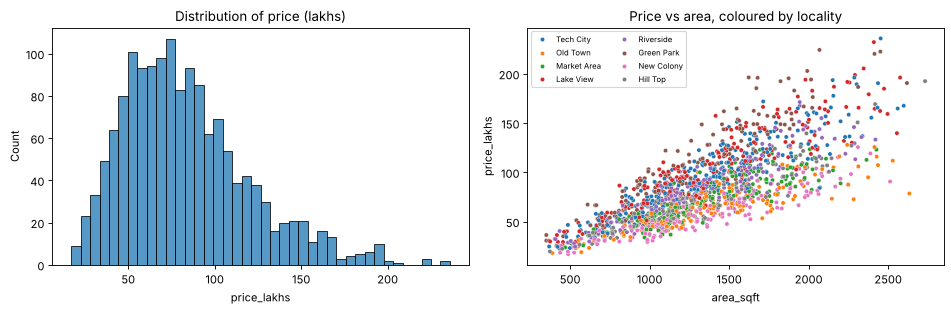

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_lakhs"], bins=40, ax=axes[0])
axes[0].set_title("Distribution of price (lakhs)")
sns.scatterplot(data=df, x="area_sqft", y="price_lakhs", hue="locality", s=15, ax=axes[1])
axes[1].set_title("Price vs area, coloured by locality")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()

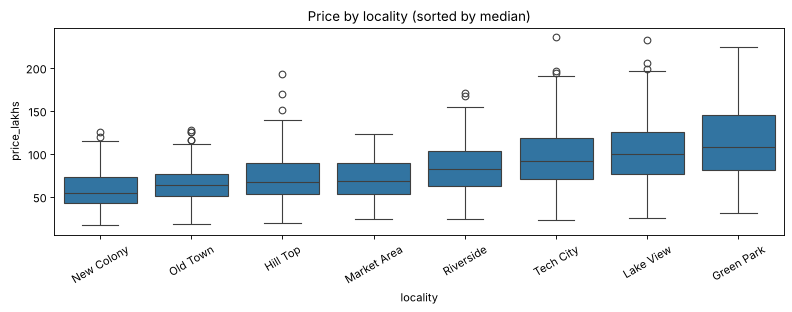

In [8]:
order = df.groupby("locality")["price_lakhs"].median().sort_values().index
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="locality", y="price_lakhs", order=order)
plt.xticks(rotation=30)
plt.title("Price by locality (sorted by median)")
plt.tight_layout()

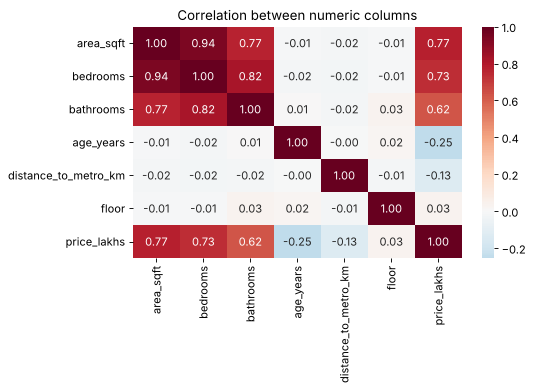

In [9]:
numeric_cols = ["area_sqft", "bedrooms", "bathrooms", "age_years", "distance_to_metro_km", "floor", "price_lakhs"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation between numeric columns")
plt.tight_layout()

**What to notice:** price rises with area, differs strongly by locality, and falls with age and distance to the metro.
Area, bedrooms and bathrooms are correlated with each other, which is normal (bigger homes have more rooms).
The price distribution is right-skewed: a few expensive homes have high prices.

## 4. Choose features and target, then split

We split **before** any fitting, and keep 20% of houses aside as a test set the model never sees during training.

In [10]:
NUMERIC = ["area_sqft", "bedrooms", "bathrooms", "age_years", "distance_to_metro_km", "floor"]
CATEGORICAL = ["locality", "parking", "furnishing"]
TARGET = "price_lakhs"

X = df[NUMERIC + CATEGORICAL]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1200, 9)  Test: (300, 9)


## 5. Build a preprocessing pipeline

- Numeric columns: fill missing values with the **median** of the training data, then standardise.
- Categorical columns: fill missing values with the **most frequent** value, then one-hot encode.
  `handle_unknown="ignore"` means a locality never seen in training will not crash the model at prediction time.

Putting preprocessing inside the pipeline guarantees it is learned from training data only, also inside cross-validation.

In [11]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 6. Train a baseline and three models

The **baseline** always predicts the average training price. Any useful model must beat it.
We report:
- **MAE** — average size of the error in lakhs (easy to explain to a buyer),
- **RMSE** — like MAE but punishes big mistakes more,
- **R²** — share of the price variation the model explains (1.0 = perfect, 0 = no better than the average).

In [12]:
def evaluate(name, model):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    return pipe, {
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    }

candidates = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
fitted, rows = {}, []
for name, model in candidates.items():
    fitted[name], scores = evaluate(name, model)
    rows.append(scores)

results = pd.DataFrame(rows).set_index("model").round(3)
results

,MAE,RMSE,R2
model,,,
Baseline (mean),28.544,37.110,-0.009
Linear Regression,7.923,10.734,0.916
Random Forest,7.646,11.108,0.910
Gradient Boosting,6.958,9.983,0.927


## 7. Check the result is stable with cross-validation

One train/test split can be lucky or unlucky. 5-fold cross-validation on the **training set** gives a more reliable
estimate and shows how much the error varies.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in ["Linear Regression", "Random Forest", "Gradient Boosting"]:
    pipe = Pipeline([("prep", preprocess), ("model", candidates[name])])
    mae = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    cv_rows.append({"model": name, "CV MAE mean": mae.mean(), "CV MAE std": mae.std()})
cv_results = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_results

,CV MAE mean,CV MAE std
model,,
Linear Regression,8.168,0.124
Random Forest,8.089,0.288
Gradient Boosting,7.094,0.250


In [14]:
best_name = cv_results["CV MAE mean"].idxmin()
best_model = fitted[best_name]
best_scores = results.loc[best_name]
print(f"Best model by cross-validated MAE: {best_name}")
print(f"Test MAE {best_scores['MAE']:.2f} lakhs, RMSE {best_scores['RMSE']:.2f}, R2 {best_scores['R2']:.3f}")
print(f"Baseline test MAE: {results.loc['Baseline (mean)', 'MAE']:.2f} lakhs")

Best model by cross-validated MAE: Gradient Boosting
Test MAE 6.96 lakhs, RMSE 9.98, R2 0.927
Baseline test MAE: 28.54 lakhs


## 8. Understand the errors

A residual is *actual price − predicted price*. A good model has residuals scattered around zero with no clear pattern.

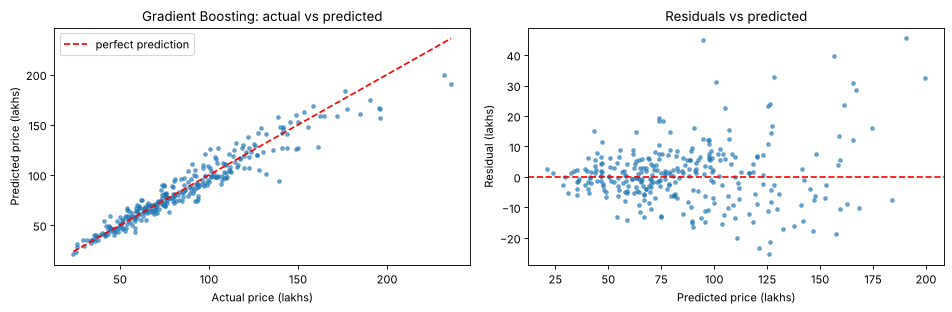

In [15]:
test_pred = best_model.predict(X_test)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, test_pred, s=10, alpha=0.6)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual price (lakhs)"); axes[0].set_ylabel("Predicted price (lakhs)")
axes[0].legend(); axes[0].set_title(f"{best_name}: actual vs predicted")
axes[1].scatter(test_pred, residuals, s=10, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted price (lakhs)"); axes[1].set_ylabel("Residual (lakhs)")
axes[1].set_title("Residuals vs predicted")
plt.tight_layout()

In [16]:
# Is the error similar for cheap and expensive homes?
bands = pd.cut(y_test, bins=[0, 50, 80, 120, 1000], labels=["<50", "50-80", "80-120", ">120"])
err = pd.DataFrame({"band": bands, "abs_error": residuals.abs(), "pct_error": (residuals.abs() / y_test * 100)})
err.groupby("band", observed=True).agg(houses=("abs_error", "size"),
                                       MAE_lakhs=("abs_error", "mean"),
                                       mean_pct_error=("pct_error", "mean")).round(1)

,houses,MAE_lakhs,mean_pct_error
band,,,
<50,43,3.1,8.1
50-80,110,4.7,7.3
80-120,100,7.5,7.7
>120,47,14.5,9.2


**Reading the table:** errors in lakhs grow for expensive homes (a 10% mistake on a ₹2 crore flat is large in rupees),
while the percentage error stays more similar across bands. This is why we also show a *range* in the app, not just a
single number.

## 9. Which features matter?

Permutation importance shuffles one column at a time on the test set and measures how much the error gets worse.
A big increase means the model relies on that column.

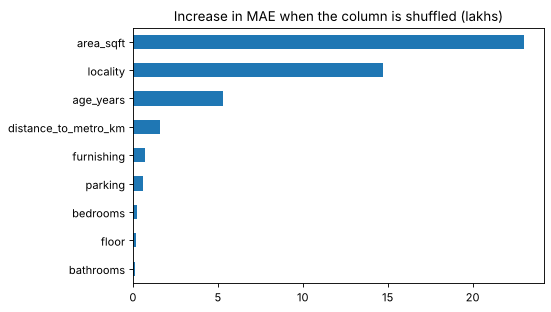

In [17]:
imp = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                             scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh(figsize=(7, 4), title="Increase in MAE when the column is shuffled (lakhs)")
plt.tight_layout()

## 10. Test new examples and edge cases

In [18]:
new_houses = pd.DataFrame([
    {"area_sqft": 1200, "bedrooms": 2, "bathrooms": 2, "age_years": 5, "distance_to_metro_km": 1.5, "floor": 4,
     "locality": "Tech City", "parking": "Yes", "furnishing": "Semi-Furnished"},
    {"area_sqft": 1200, "bedrooms": 2, "bathrooms": 2, "age_years": 5, "distance_to_metro_km": 1.5, "floor": 4,
     "locality": "New Colony", "parking": "Yes", "furnishing": "Semi-Furnished"},
    # missing age (the pipeline fills it with the training median)
    {"area_sqft": 2500, "bedrooms": 4, "bathrooms": 3, "age_years": np.nan, "distance_to_metro_km": 6.0, "floor": 10,
     "locality": "Green Park", "parking": "No", "furnishing": "Fully-Furnished"},
    # a locality the model has never seen (ignored by one-hot encoding)
    {"area_sqft": 1000, "bedrooms": 2, "bathrooms": 1, "age_years": 12, "distance_to_metro_km": 3.0, "floor": 1,
     "locality": "Airport Road", "parking": "No", "furnishing": "Unfurnished"},
])
new_houses["predicted_price_lakhs"] = best_model.predict(new_houses).round(1)
new_houses[["locality", "area_sqft", "age_years", "predicted_price_lakhs"]]

,locality,area_sqft,age_years,predicted_price_lakhs
0,Tech City,1200,5.0,98.1
1,New Colony,1200,5.0,60.3
2,Green Park,2500,NaN,169.1
3,Airport Road,1000,12.0,52.9


The same house is predicted to cost much more in Tech City than in New Colony, as expected.
The unseen locality still gets a prediction, but it is only based on the other columns, so it is less reliable.
**The API therefore rejects unknown localities** with a clear message instead of silently guessing.

## 11. Save the model and the information the API needs

We save the **whole pipeline** (preprocessing + model), so the API sends raw values and gets a price back.
`model_info.json` stores the allowed values and ranges for input validation, and the test MAE for the price range.

In [19]:
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/house_price_model.joblib")

clean_train = X_train.dropna()
model_info = {
    "model_name": best_name,
    "target": TARGET,
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "categories": {c: sorted(df[c].dropna().unique().tolist()) for c in CATEGORICAL},
    "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in NUMERIC},
    "test_metrics": {k: round(float(v), 3) for k, v in best_scores.items()},
    "baseline_test_mae": round(float(results.loc["Baseline (mean)", "MAE"]), 3),
    "train_rows": int(len(X_train)),
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print(json.dumps(model_info["test_metrics"], indent=2))
print(sorted(os.listdir("models")))

{
  "MAE": 6.958,
  "RMSE": 9.983,
  "R2": 0.927
}
['house_price_model.joblib', 'model_info.json']


In [20]:
# Reload from disk exactly as the API will, and check predictions match
reloaded = joblib.load("models/house_price_model.joblib")
assert np.allclose(reloaded.predict(X_test.head(5)), best_model.predict(X_test.head(5)))
print("Reloaded model gives identical predictions.")

Reloaded model gives identical predictions.


## 12. Limitations and possible improvements

- **Synthetic data.** The patterns are realistic but invented; a real project would use real transactions and check for
  data quality issues such as wrong areas or prices typed in rupees instead of lakhs.
- **Out-of-range inputs.** The model has only seen 350–4,200 sq ft. Tree models cannot extrapolate, so the API refuses
  values outside the training ranges.
- **Unseen localities** get unreliable predictions; the API rejects them.
- **Prices change over time.** A model trained on old sales must be retrained regularly.
- **Improvements to try:** predict `log(price)` to handle skew, tune hyperparameters with `GridSearchCV`, add features
  such as amenities or exact coordinates, and report prediction intervals with quantile regression.

**Next step:** start the Flask API in `backend/` (see the project README). It loads the two files saved above.